# Micro, macro and imbalance

Three things that go wrong when a model is evaluated on imbalanced classes, each shown with
a model that looks fine by accuracy:

1. micro-precision, micro-recall and micro-$F_1$ are all just accuracy on single-label data;
2. a micro-averaged measure can lie *outside* the range of its per-class values, so it is not
   a weighted average of them;
3. when a class is never predicted, the value of a macro average depends on a hidden choice
   for $0/0$.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

from aggmetrics import IndicatorMatrix, diagnose
from aggmetrics.diagnostics import check_hull

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## An imbalanced digits problem

`digits` has about 180 examples per class. We keep a geometric-looking profile, from 170
examples of class 0 down to 5 of class 9, and train a regularised logistic regression.

In [3]:
X, y = load_digits(return_X_y=True)
keep = {0: 170, 1: 120, 2: 85, 3: 60, 4: 42, 5: 30, 6: 20, 7: 14, 8: 9, 9: 5}
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.flatnonzero(y == c), k, replace=False) for c, k in keep.items()])
X, y = X[idx] / 16.0, y[idx]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, stratify=y, random_state=0)

clf = LogisticRegression(C=0.1, max_iter=3000).fit(Xtr, ytr)
pred = clf.predict(Xte)
im = IndicatorMatrix(yte, pred, task="multiclass", n_classes=10)

print("test examples per class :", np.bincount(yte))
print("predictions per class   :", np.bincount(pred, minlength=10))
print("accuracy                :", round(accuracy_score(yte, pred), 3))

test examples per class : [85 60 43 30 21 15 10  7  5  2]
predictions per class   : [95 75 43 26 22 12  3  2  0  0]
accuracy                : 0.892


Accuracy is 0.89, and the model never predicts classes 8 and 9. Keep that in mind.

## 1. Micro-averaging collapses to accuracy

On single-label data every error is one false positive for the predicted class and one false
negative for the true class, so the pooled counts satisfy `fp = fn`. Then micro-precision,
micro-recall and micro-$F_1$ are all equal to accuracy: reporting the three conveys one number.

In [4]:
summary = pd.Series({
    "accuracy": im.accuracy(),
    "micro precision": im.compute("precision", "micro"),
    "micro recall": im.compute("recall", "micro"),
    "micro F1": im.compute("f1", "micro"),
    "macro F1": im.compute("f1", "macro"),
    "macro recall (balanced accuracy)": im.compute("recall", "macro"),
}).round(4)
assert np.allclose(summary.iloc[:4], summary.iloc[0])
summary

accuracy                            0.8921
micro precision                     0.8921
micro recall                        0.8921
micro F1                            0.8921
macro F1                            0.6398
macro recall (balanced accuracy)    0.6123
dtype: float64

The first four rows are identical by construction. The macro rows, which give each class the
same weight, tell a different story. `scikit-learn` agrees on the micro rows:

In [5]:
for name, fn in (("precision", precision_score), ("recall", recall_score), ("f1", f1_score)):
    print(f"sklearn micro {name:9s}:", round(fn(yte, pred, average="micro"), 4))

sklearn micro precision: 0.8921
sklearn micro recall   : 0.8921
sklearn micro f1       : 0.8921


## 2. Micro can lie outside the per-class range

For a measure whose numerator and denominator are linear in the counts (precision, recall,
$F_1$, ...), micro-averaging is a weighted average of the per-class values, so it lies between
their minimum and maximum. For others (MCC, balanced accuracy, G-mean) that identity fails,
and the pooled value can fall *outside* the range of the per-class values: no weighting of
the classes reproduces it.

A small example with three classes:

In [6]:
y_toy = [2, 1, 1, 0, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1]
p_toy = [1, 1, 1, 2, 1, 1, 1, 0, 1, 1, 1, 1, 2, 2, 1]
toy = IndicatorMatrix(y_toy, p_toy, task="multiclass")

per_class = toy.parts("mcc", "macro")
micro = toy.compute("mcc", "micro")
print("per-class MCC :", per_class.round(4))
print("micro MCC     :", round(micro, 4))
print(check_hull(toy, "mcc"))

per-class MCC : [-0.0714  0.3182  0.1667]
micro MCC     : 0.5
[warning] outside_hull: micro-mcc = 0.5000 lies outside the range of the per-class values [-0.0714, 0.3182], so it is not a weighted average of them. 'mcc' is not aggregation-decomposable.


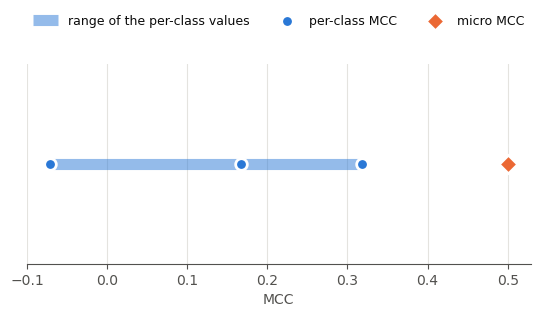

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.hlines(0, per_class.min(), per_class.max(), color=BLUE, linewidth=8, alpha=0.5,
          label="range of the per-class values")
ax.scatter(per_class, np.zeros_like(per_class), s=70, color=BLUE, zorder=3,
           edgecolor="white", linewidth=2, label="per-class MCC")
ax.scatter([micro], [0], s=90, color=ORANGE, marker="D", zorder=3,
           edgecolor="white", linewidth=2, label="micro MCC")
ax.set_yticks([])
ax.set_xlabel("MCC")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.3), ncol=3, fontsize=9)
plt.show()

The micro value is above every per-class value. `diagnose` runs this check for each measure
you ask about, and `check_hull` is the single-measure version. On the imbalanced digits model
it does not fire; it needs a particular error pattern:

In [8]:
for name in ("mcc", "balanced_accuracy", "gmean", "informedness", "kappa"):
    print(f"{name:18s}", "outside the per-class range" if check_hull(im, name) else "inside")

mcc                inside
balanced_accuracy  inside
gmean              inside
informedness       inside
kappa              inside


## 3. A class that is never predicted

Precision for classes 8 and 9 is $0/0$: nothing was predicted as either. A macro average needs a
value for it, and the choice changes the result. `aggmetrics` makes the choice an explicit
argument; `scikit-learn` makes it `zero_division`.

In [9]:
rows = {}
for conv in ("exclude", "zero", "one", "nan"):
    rows[conv] = {m: im.compute(m, "macro", convention=conv) for m in ("precision", "recall", "f1")}
pd.DataFrame(rows).T.round(4)

,precision,recall,f1
exclude,0.9383,0.6123,0.6398
zero,0.7506,0.6123,0.6398
one,0.9506,0.6123,0.6398
nan,NaN,0.6123,0.6398


`exclude` averages over the eight classes where the value exists, `zero` counts the undefined class
as 0 (this is `zero_division=0`), `one` counts it as 1, and `nan` returns NaN rather than a
guess. `scikit-learn` with `zero_division=0` matches the `zero` row:

In [10]:
print("sklearn precision, macro, zero_division=0 :",
      round(precision_score(yte, pred, average="macro", zero_division=0), 4))
print("aggmetrics convention='zero'                 :",
      round(im.compute("precision", "macro", convention="zero"), 4))

sklearn precision, macro, zero_division=0 : 0.7506
aggmetrics convention='zero'                 : 0.7506


`diagnose` reports the size of the effect, so the choice does not stay hidden:

In [11]:
for f in diagnose(im, ["precision", "f1"]):
    if f.code == "undefined_entries":
        print(f)

[warning] undefined_entries: macro-precision has 2 of 10 undefined entries; the reported value is 0.9383 under the exclusion convention and 0.7506 under substitution of zero (difference 0.1877).


## What to report

- State the averaging operator next to every number: "macro-$F_1$", not "$F_1$".
- On imbalanced data, report macro recall or per-class recall next to accuracy.
- Never report micro-precision, micro-recall and micro-$F_1$ together on single-label data.
- Declare the `convention` for undefined entries, or let `diagnose` print the difference.

Next: *03 Multilabel: the ranking depends on the operator*.